## Домашнее задание #1 

Датасет выбрал: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset?utm_source=chatgpt.com

У нас 17 признаков, прогнозируем boolean значение Revenue - бинарная классификация.
Гипотезы до начала работы:
- H1: Логистическая регрессия покажет результат хуже чем Random Forest на ROC-AUC, так как скорее всего между поведением покупателя и фактом покупки нелинейная зависимость
- H2: Из 17 отбор примерно 5 самых информативных признаков сохранит не менее 95% скора полной модели на ROC-AUC
- H3: Если вдруг классы в датасете будут несбалансированы, то исправление этого в train set (class_weight="balanced") улучшит Recall
- H4: XGBoost покажет еще лучший ROC-AUC чем ЛогРег и RF
- H5: Деревья с макс глубиной > 15 переобучатся по сравнению с max_depth = 5 (будет разрыв между train set accuracy и accuracy на val) 

In [117]:
%pip install pandas numpy matplotlib scikit-learn xgboost


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: /Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sklearn.inspection import permutation_importance

In [119]:
df = pd.read_csv('data/online_shoppers_intention.csv')

In [120]:
print(df.shape)
print(df.dtypes)

(12330, 18)
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object


In [121]:
print(df.describe(include='all'))

        Administrative  Administrative_Duration  Informational  \
count     12330.000000             12330.000000   12330.000000   
unique             NaN                      NaN            NaN   
top                NaN                      NaN            NaN   
freq               NaN                      NaN            NaN   
mean          2.315166                80.818611       0.503569   
std           3.321784               176.779107       1.270156   
min           0.000000                 0.000000       0.000000   
25%           0.000000                 0.000000       0.000000   
50%           1.000000                 7.500000       0.000000   
75%           4.000000                93.256250       0.000000   
max          27.000000              3398.750000      24.000000   

        Informational_Duration  ProductRelated  ProductRelated_Duration  \
count             12330.000000    12330.000000             12330.000000   
unique                     NaN             NaN           

In [122]:
print(df.duplicated().sum())

125


In [123]:
df['Revenue'] = df['Revenue'].astype(str).str.strip().str.lower().map({'true': 1, '1': 1, 'false': 0, '0': 0})
assert df['Revenue'].notna().all()

X = df.drop(columns=['Revenue'])
y = df['Revenue'].astype(int)

print(X.shape, y.shape)

(12330, 17) (12330,)


In [124]:
# 60/20/20 split

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(7398, 17) (7398,)
(2466, 17) (2466,)
(2466, 17) (2466,)


In [125]:
train_df = X_train.copy()
train_df['Revenue'] = y_train

### EDA

In [126]:
print(df.isna().sum()) # класс

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [127]:
print(df['Revenue'].value_counts(normalize=True)) #  предиктор False всегда уже достиг бы 0.845 acc
# -> будем смотреть на PR-AUC скорее

Revenue
0    0.845255
1    0.154745
Name: proportion, dtype: float64


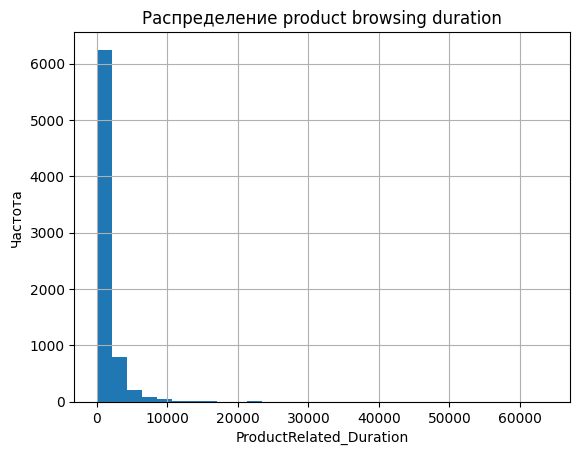

In [128]:
train_df["ProductRelated_Duration"].hist(bins=30)

plt.xlabel("ProductRelated_Duration")
plt.ylabel("Частота")
plt.title("Распределение product browsing duration")
plt.show()

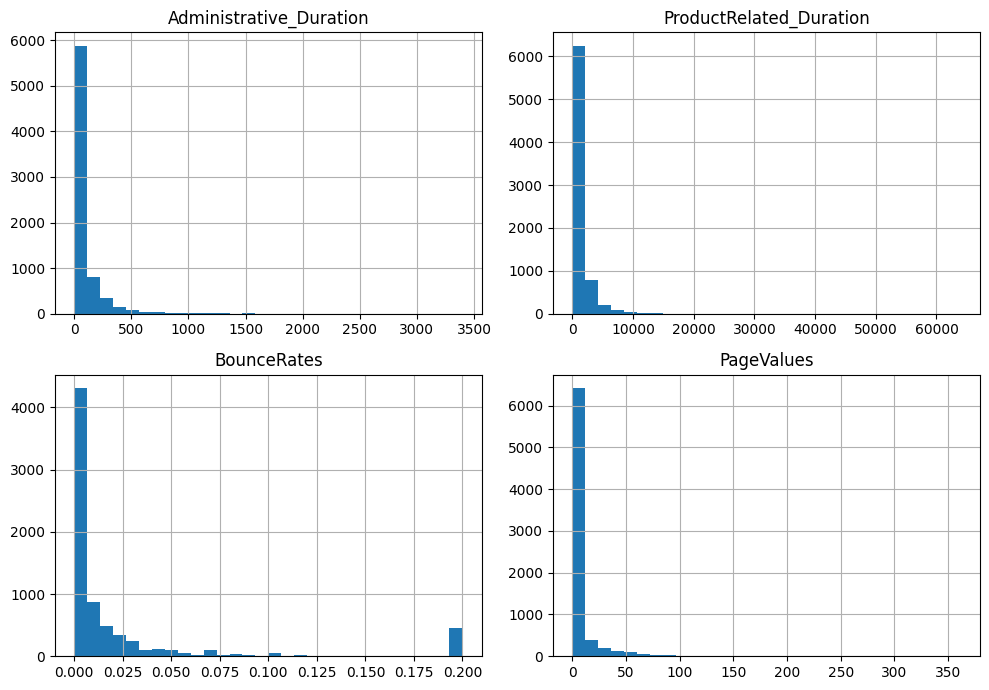

In [129]:
columns = [
    "Administrative_Duration",
    "ProductRelated_Duration",
    "BounceRates",
    "PageValues"
]

train_df[columns].hist(
    bins=30,
    figsize=(10, 7)
)

plt.tight_layout()
plt.show()

In [130]:
# Определенные признаки (выделил тут в cat_cols) по смыслу категории
cat_cols = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

num_cols = [c for c in X.columns if c not in cat_cols]

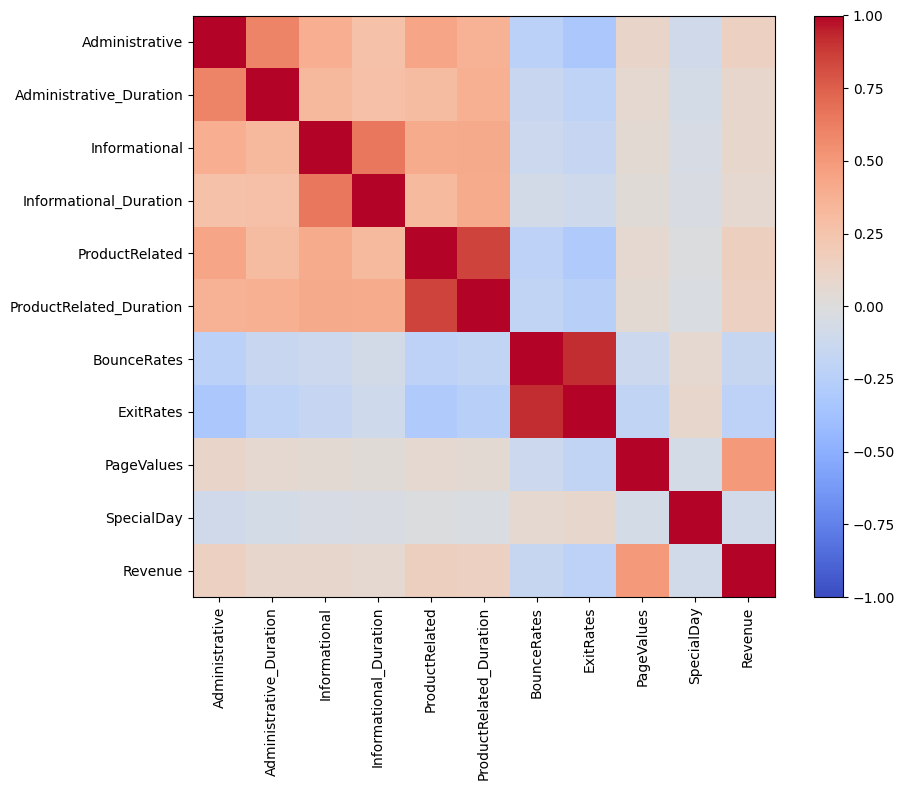

In [131]:
corr = train_df[num_cols + ['Revenue']].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

plt.colorbar()
plt.tight_layout()
plt.show()

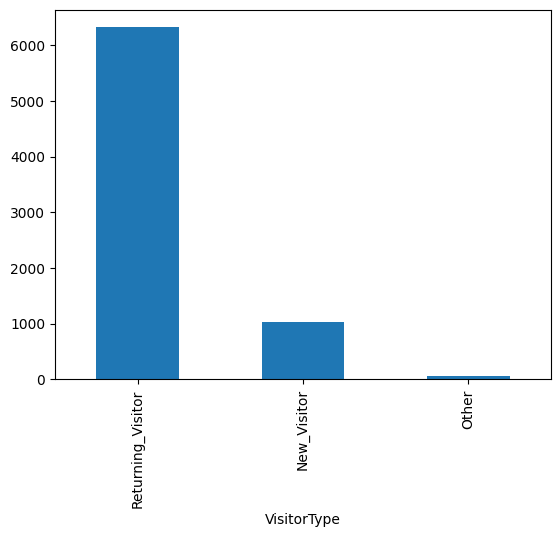

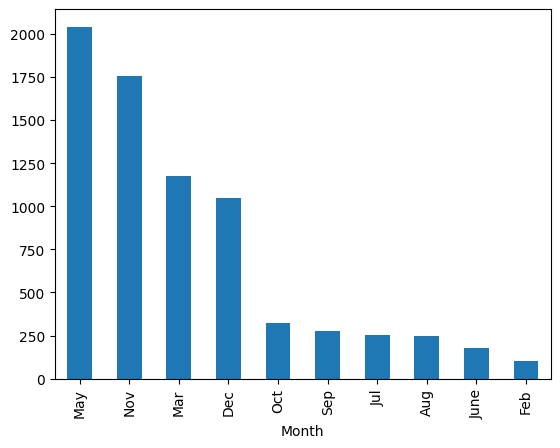

In [132]:
train_df["VisitorType"].value_counts().plot.bar()
plt.show()

train_df["Month"].value_counts().plot.bar()
plt.show()

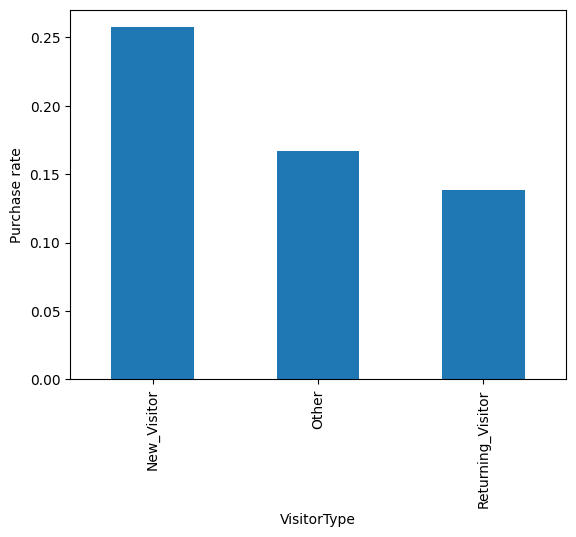

In [133]:
# VisitorType звучит как информативная фича
train_df.groupby("VisitorType")["Revenue"].mean().plot.bar()

plt.ylabel("Purchase rate")
plt.show()

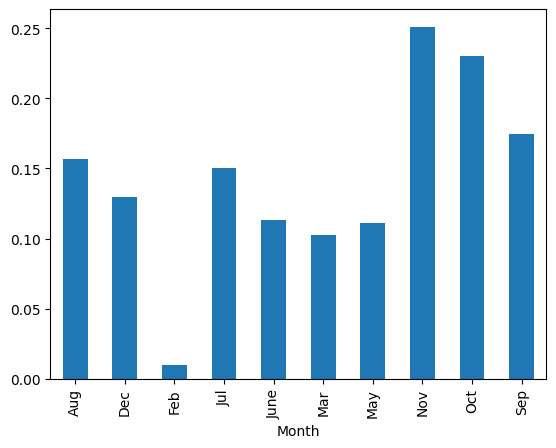

In [134]:
train_df.groupby("Month")["Revenue"].mean().plot.bar()
plt.show()

### Preprocessing

In [135]:
# Для числовых всегда SimpleImputer (у нас все не нули правда) + StandardScaler, для категорий (SimpleImputer +) OneHotEncoder
# это можно обернуть в build_pipeline 

In [136]:
def build_pipeline(estimator, columns=None):
    cols = list(X.columns) if columns is None else list(columns)

    num = [c for c in cols if c in num_cols]
    cat = [c for c in cols if c in cat_cols]

    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocess = ColumnTransformer([
        ("num", num_pipeline, num),
        ("cat", cat_pipeline, cat)
    ])

    return Pipeline([
        ("preprocess", preprocess),
        ("model", estimator)
    ])

### Модели

In [137]:
# для гипотез выбрал логрег, RF, XGBoost, предварительные гиперпараметры
models = {
    "LogReg": LogisticRegression(
        max_iter=2000
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    )
}

In [138]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [139]:
cv_results = []

for name, estimator in models.items():
    pipe = build_pipeline(estimator)

    scores = cross_validate(
        pipe,
        X_train, y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "pr_auc": "average_precision", 
            "recall": "recall"
        },
        n_jobs=1
    )

    cv_results.append({
        "model": name,
        "roc_auc": scores["test_roc_auc"].mean(),
        "pr_auc": scores["test_pr_auc"].mean(),
        "recall": scores["test_recall"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)
cv_df

,model,roc_auc,pr_auc,recall,roc_auc_std
0,LogReg,0.891481,0.638113,0.393013,0.016468
1,RandomForest,0.922354,0.734420,0.505677,0.013645
2,XGBoost,0.932000,0.746225,0.598253,0.010417


In [140]:
fitted = {}

for name, estimator in models.items():
    pipe = build_pipeline(clone(estimator))
    pipe.fit(X_train, y_train)

    fitted[name] = pipe

In [141]:
def evaluate(model, X_data, y_data):
    proba = model.predict_proba(X_data)[:, 1]
    pred = (proba >= 0.5).astype(int)

    return {
        "roc_auc": roc_auc_score(y_data, proba),
        "pr_auc": average_precision_score(y_data, proba),
        "precision": precision_score(
            y_data, pred, zero_division=0
        ),
        "recall": recall_score(
            y_data, pred, zero_division=0
        ),
        "f1": f1_score(
            y_data, pred, zero_division=0
        )
    }

In [142]:
val_results = []

for name, model in fitted.items():
    result = evaluate(model, X_val, y_val)
    val_results.append({
        "model": name,
        **result
    })

val_df = pd.DataFrame(val_results)
val_df

,model,roc_auc,pr_auc,precision,recall,f1
0,LogReg,0.889662,0.659729,0.746341,0.401575,0.522184
1,RandomForest,0.925391,0.738166,0.757463,0.532808,0.625578
2,XGBoost,0.932229,0.739418,0.705167,0.608924,0.653521


Можем уже сделать выводы по двум гипотезам (H1 и H4):
- И правда, XGB > RF > LogReg, с ROC-AUC значениями 0.932, 0.925 и 0.890 соответственно.

### Проверяем остальные гипотезы

#### H2: 5 наиболее информативных признаков сохранят 95% ROC-AUC

Можем здесь использовать permutation importance, это один из главных способов понять практически важен ли признак - мы выбираем признак (сделаем так со всеми 17), и перемешиваем его по строкам, нарушая порядок. И если итоговый скор модели не сильно поменялся от тренировки на таких данных, то этот признак не был сильно информативен. И наоборот.

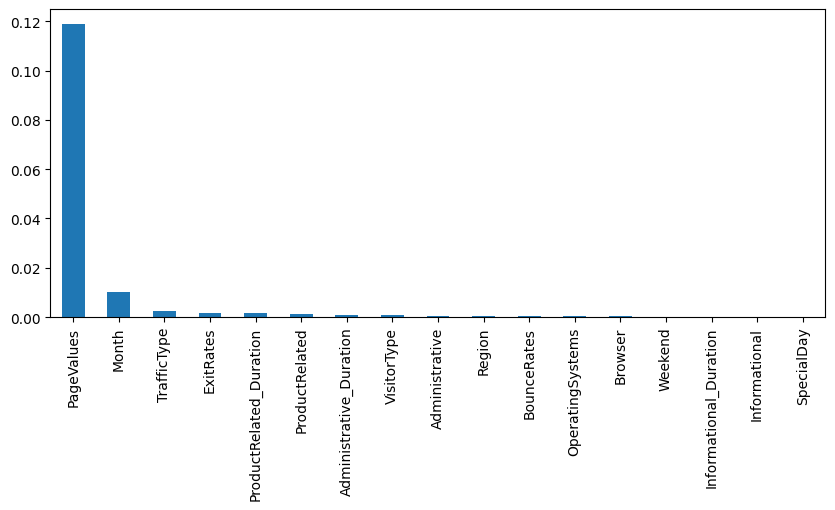

In [143]:
perm = permutation_importance(
    fitted["RandomForest"],
    X_train,
    y_train,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=2
)

importance = pd.Series(
    perm.importances_mean,
    index=X_train.columns
).sort_values(ascending=False)

importance.plot.bar(figsize=(10, 4))
plt.show()

In [144]:
# глядя на график, можем взять даже 3 :))
top3 = importance.head(3).index.tolist()

print(top3)

['PageValues', 'Month', 'TrafficType']


In [145]:
rf_top3 = build_pipeline(
    RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),
    columns=top3
)

rf_top3.fit(X_train[top3], y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['PageValues','Month','TrafficType']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specifie

In [146]:
full_score = evaluate(
    fitted["RandomForest"], X_val, y_val
)["roc_auc"]

top3_score = evaluate(
    rf_top3, X_val[top3], y_val
)["roc_auc"]

print("Full:", full_score)
print("Top 3:", top3_score)
print("Ratio:", top3_score / full_score)

Full: 0.9253913404709303
Top 3: 0.8930978052203906
Ratio: 0.9651028339706469


Как мы видим, даже 3 самых информативных признака сохранили больше 96% процентов скора. Ну и гляда на график, можем видеть что PageValues тотально доминирует как определяющий признак. Гипотеза 2 подтвердилась.

#### H3: Балансирование классов повысит Recall

In [147]:
lr_normal = build_pipeline(
    LogisticRegression(
        max_iter=2000
    )
)

lr_balanced = build_pipeline(
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    )
)

lr_normal.fit(X_train, y_train)
lr_balanced.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [148]:
print("Normal:")
print(evaluate(lr_normal, X_val, y_val))

print("Balanced:")
print(evaluate(lr_balanced, X_val, y_val))

Normal:
{'roc_auc': 0.8896618138560017, 'pr_auc': 0.6597288895018949, 'precision': 0.7463414634146341, 'recall': 0.4015748031496063, 'f1': 0.5221843003412969}
Balanced:
{'roc_auc': 0.9030898116152747, 'pr_auc': 0.6731201665204738, 'precision': 0.4909090909090909, 'recall': 0.7795275590551181, 'f1': 0.6024340770791075}


И правда: Recall вырос с 0.40 до 0.78 только после балансировки таргетов. Важно сказать, что это произошло  ценой precision: 0.77 -> 0.49.

#### Глубокое дерево сильнее оверфиттит

In [149]:
for depth in [5, 15]:
    model = build_pipeline(
        DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )

    val_acc = accuracy_score(
        y_val, model.predict(X_val)
    )

    print(
        depth,
        "Train:", train_acc,
        "Validation:", val_acc,
        "Gap:", train_acc - val_acc
    )

5 Train: 0.9115977291159773 Validation: 0.8929440389294404 Gap: 0.018653690186536842
15 Train: 0.9920248715869154 Validation: 0.8759124087591241 Gap: 0.11611246282779131


Эта гипотеза тоже подтверждается: наш gap с 0.019 повысился до 0.116.

#### Категориальные фичи повышают скор LogReg

In [150]:
lr_numeric = build_pipeline(
    LogisticRegression(max_iter=2000),
    columns=num_cols
)

lr_numeric.fit(X_train[num_cols], y_train)

/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:3

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Administrative','Administrative_Duration','Informational',..., 'ExitRates','PageValues','SpecialDay']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [151]:
numeric_result = evaluate(
    lr_numeric,
    X_val[num_cols],
    y_val
)

full_result = evaluate(
    fitted["LogReg"],
    X_val,
    y_val
)

print("Numeric only:", numeric_result)
print("All features:", full_result)

Numeric only: {'roc_auc': 0.8920196126563317, 'pr_auc': 0.6687440946668053, 'precision': 0.7409326424870466, 'recall': 0.3753280839895013, 'f1': 0.49825783972125437}
All features: {'roc_auc': 0.8896618138560017, 'pr_auc': 0.6597288895018949, 'precision': 0.7463414634146341, 'recall': 0.4015748031496063, 'f1': 0.5221843003412969}


/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/artemiysenyuk/Projects/JupyterNotebooks/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Не совсем. Можно считать, что здесь перформанс практически тот же - помним, что у нас по сути лишь 1 информативный признак (который не категориальный).

### Гиперпараметры

In [152]:
rf_search = GridSearchCV(
    estimator=build_pipeline(
        RandomForestClassifier(
            n_estimators=150,
            random_state=42,
            n_jobs=-1
        )
    ),
    param_grid={
        "model__max_depth": [6, 12, None],
        "model__min_samples_leaf": [1, 4]
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=1
)

rf_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [6, 12, ...], 'model__min_samples_leaf': [1, 4]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defau

In [153]:
print(rf_search.best_params_)
print(rf_search.best_score_)

tuning_df = pd.DataFrame(rf_search.cv_results_)

tuning_df[
    ["params", "mean_test_score", "std_test_score"]
].sort_values("mean_test_score", ascending=False)

{'model__max_depth': 12, 'model__min_samples_leaf': 1}
0.9230368958283155


,params,mean_test_score,std_test_score
2,"{'model__max_depth': 12, 'model__min_samples_l...",0.923037,0.013245
3,"{'model__max_depth': 12, 'model__min_samples_l...",0.922818,0.012974
5,"{'model__max_depth': None, 'model__min_samples...",0.922510,0.014935
4,"{'model__max_depth': None, 'model__min_samples...",0.921431,0.013441
1,"{'model__max_depth': 6, 'model__min_samples_le...",0.914669,0.014409
0,"{'model__max_depth': 6, 'model__min_samples_le...",0.913585,0.014189


In [154]:
# и лучшая модель из протестированных:
rf_tuned = rf_search.best_estimator_

print(evaluate(rf_tuned, X_val, y_val))

{'roc_auc': 0.9266325522259358, 'pr_auc': 0.7439804712791939, 'precision': 0.7792207792207793, 'recall': 0.47244094488188976, 'f1': 0.5882352941176471}


### Финально: берем XGBoost

In [155]:
candidates = {
    **fitted,
    "RF_tuned": rf_tuned
}

best_name = max(
    candidates,
    key=lambda name: evaluate(
        candidates[name], X_val, y_val
    )["roc_auc"]
)

print("Selected model:", best_name)

Selected model: XGBoost


In [156]:
final_model = clone(candidates[best_name])

final_model.fit(X_dev, y_dev)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [157]:
final_result = evaluate(
    final_model,
    X_test,
    y_test
)

print(final_result)

{'roc_auc': 0.9320590186009586, 'pr_auc': 0.7488471632173926, 'precision': 0.7307692307692307, 'recall': 0.5968586387434555, 'f1': 0.6570605187319885}


In [158]:
# Можно посмотреть на confusion matrix
pred = final_model.predict(X_test)

cm = confusion_matrix(y_test, pred)

print(cm)

[[2000   84]
 [ 154  228]]
